# Task 4 (Evaluate and Explain)

For all four models (scratch Perceptron, scratch Logistic, sklearn Perceptron, sklearn Logistic) we compute on the **held-out test set**:
confusion matrix, accuracy, precision, recall and F1. We implement the metrics **manually** and verify them against scikit-learn, present a compact comparison table, and choose the preferable model for a screening setting where **missing a positive case is more costly than a false alarm**. The choice is not based on test accuracy alone.

Class convention: **positive = 1 = diabetes (Outcome = 1)**.

## 0. Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load Prepared Data (Task 1) and Re-create All Four Models (Tasks 2 and 3)

Same data, same hyper-parameters and same seeds as in the previous tasks, so the predictions are identical to those already seen. (Everything is rebuilt here only so the notebook can run on its own.)

In [2]:
if os.path.exists("prepared_diabetes_data.npz"):
    d = np.load("prepared_diabetes_data.npz", allow_pickle=True)
    X_train, X_test = d["X_train"], d["X_test"]
    y_train, y_test = d["y_train"], d["y_test"]
    FEATURES = [str(f) for f in d["features"]]
    print("Loaded prepared_diabetes_data.npz")
else:
    from sklearn.model_selection import train_test_split
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler

    COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    if os.path.exists("diabetes.csv"):
        df = pd.read_csv("diabetes.csv")
    else:
        url = ("https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
               "pima-indians-diabetes.data.csv")
        df = pd.read_csv(url, header=None, names=COLS)

    FEATURES = ["Glucose", "BMI"]
    df[["Glucose", "BMI"]] = df[["Glucose", "BMI"]].replace(0, np.nan)
    Xr, yr = df[FEATURES], df["Outcome"]
    Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.20, stratify=yr,
                                          random_state=RANDOM_STATE)
    imp = SimpleImputer(strategy="median").fit(Xtr)
    sc = StandardScaler().fit(imp.transform(Xtr))
    X_train = sc.transform(imp.transform(Xtr)); X_test = sc.transform(imp.transform(Xte))
    y_train = ytr.to_numpy().astype(int);       y_test = yte.to_numpy().astype(int)
    print("Rebuilt the Task 1 data pipeline")

print("Test set: %d samples, %d positive (%.1f%%), %d negative" %
      (len(y_test), y_test.sum(), 100 * y_test.mean(), (1 - y_test).sum()))

Loaded prepared_diabetes_data.npz
Test set: 154 samples, 54 positive (35.1%), 100 negative


In [3]:
class PerceptronScratch:
    def __init__(self, lr=0.1, max_epochs=100, random_state=42):
        self.lr, self.max_epochs, self.random_state = lr, max_epochs, random_state
    @staticmethod
    def step(z): return (np.asarray(z) >= 0).astype(int)
    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n, m = X.shape
        self.w, self.b = np.zeros(m), 0.0
        for epoch in range(self.max_epochs):
            errors = 0
            for i in rng.permutation(n):
                error = y[i] - int(self.step(X[i] @ self.w + self.b))
                if error != 0:
                    self.w += self.lr * error * X[i]; self.b += self.lr * error; errors += 1
            if errors == 0: break
        return self
    def predict(self, X): return self.step(X @ self.w + self.b)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def log_loss_manual(y_true, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

class LogisticRegressionScratch:
    def __init__(self, lr=0.1, max_epochs=5000, tol=1e-9):
        self.lr, self.max_epochs, self.tol = lr, max_epochs, tol
    def fit(self, X, y):
        n, m = X.shape
        self.w, self.b = np.zeros(m), 0.0
        hist = []
        for epoch in range(self.max_epochs):
            p = sigmoid(X @ self.w + self.b)
            hist.append(log_loss_manual(y, p))
            self.w -= self.lr * (X.T @ (p - y) / n); self.b -= self.lr * np.mean(p - y)
            if epoch > 0 and abs(hist[-2] - hist[-1]) < self.tol: break
        return self
    def predict_proba(self, X): return sigmoid(X @ self.w + self.b)
    def predict(self, X, threshold=0.5): return (self.predict_proba(X) >= threshold).astype(int)

perc_scratch  = PerceptronScratch(lr=0.1, max_epochs=100, random_state=RANDOM_STATE).fit(X_train, y_train)
logit_scratch = LogisticRegressionScratch(lr=0.1, max_epochs=5000, tol=1e-9).fit(X_train, y_train)
perc_sk  = Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE).fit(X_train, y_train)
logit_sk = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)

test_pred = {
    "Scratch Perceptron": perc_scratch.predict(X_test),
    "Scratch Logistic":   logit_scratch.predict(X_test),
    "sklearn Perceptron": perc_sk.predict(X_test),
    "sklearn Logistic":   logit_sk.predict(X_test),
}
for name, p in test_pred.items():
    print(f"{name:20s} first 5 predictions: {p[:5].tolist()}")
print(f"{'True labels':20s} first 5 labels     : {y_test[:5].tolist()}")

Scratch Perceptron   first 5 predictions: [1, 0, 0, 0, 0]
Scratch Logistic     first 5 predictions: [1, 0, 0, 0, 0]
sklearn Perceptron   first 5 predictions: [1, 0, 0, 1, 0]
sklearn Logistic     first 5 predictions: [1, 0, 0, 0, 0]
True labels          first 5 labels     : [0, 0, 0, 1, 0]


## 2. Metrics Implemented Manually

From the confusion matrix (rows = true class, columns = predicted class) with positive = 1:

|  | Predicted 0 | Predicted 1 |
|---|---|---|
| **True 0** | TN | FP |
| **True 1** | FN | TP |

- Accuracy = (TP + TN) / (TP + TN + FP + FN)
- Precision = TP / (TP + FP) — of the cases we flag, how many are truly positive
- Recall (sensitivity) = TP / (TP + FN) — of the truly positive cases, how many we catch
- F1 = 2 · Precision · Recall / (Precision + Recall)

Zero-division is handled explicitly (returns 0 when a denominator is 0), matching scikit-learn's `zero_division=0`.

In [4]:
def confusion_matrix_manual(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])

def metrics_manual(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_manual(y_true, y_pred)
    total = tn + fp + fn + tp
    accuracy  = (tp + tn) / total
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1}

## 3. Verification Against scikit-learn

We compare the manual implementation with scikit-learn for **all four models** (the task only requires one).

In [5]:
verify_rows = []
for name, p in test_pred.items():
    man = metrics_manual(y_test, p)
    sk = {
        "Accuracy":  accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, zero_division=0),
        "Recall":    recall_score(y_test, p, zero_division=0),
        "F1":        f1_score(y_test, p, zero_division=0),
    }
    cm_ok = np.array_equal(confusion_matrix_manual(y_test, p), confusion_matrix(y_test, p))
    ok = cm_ok and all(np.isclose(man[k], sk[k]) for k in sk)
    verify_rows.append({"Model": name, "confusion matrix equal": cm_ok,
                        "max |manual - sklearn|": max(abs(man[k] - sk[k]) for k in sk),
                        "all metrics match": ok})
    assert ok, f"Mismatch for {name}"
verify = pd.DataFrame(verify_rows).set_index("Model")
print(verify.to_string())
print("\nManual metrics match scikit-learn for all four models.")

                    confusion matrix equal  max |manual - sklearn|  all metrics match
Model                                                                                
Scratch Perceptron                    True                     0.0               True
Scratch Logistic                      True                     0.0               True
sklearn Perceptron                    True                     0.0               True
sklearn Logistic                      True                     0.0               True

Manual metrics match scikit-learn for all four models.


## 4. Confusion Matrices of the Four Models

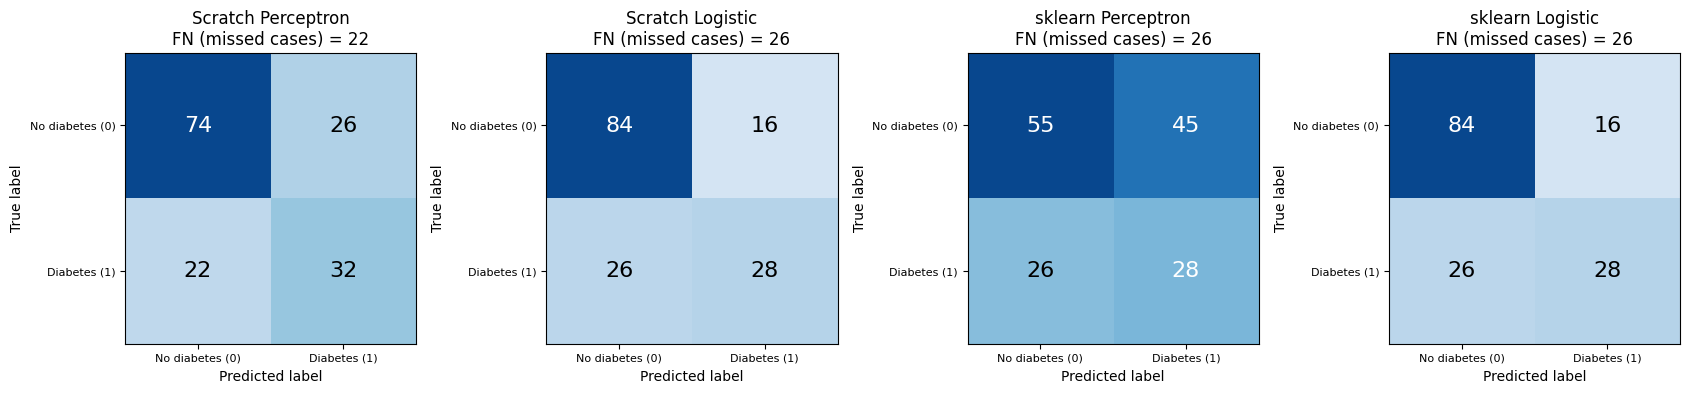

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (name, p) in zip(axes, test_pred.items()):
    cm = confusion_matrix_manual(y_test, p)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No diabetes (0)", "Diabetes (1)"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["No diabetes (0)", "Diabetes (1)"], fontsize=8)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    ax.set_title(f"{name}\nFN (missed cases) = {cm[1, 0]}")
plt.tight_layout(); plt.show()

## 5. Compact Comparison Table

In [7]:
rows = {}
for name, p in test_pred.items():
    m = metrics_manual(y_test, p)
    rows[name] = m
results = pd.DataFrame(rows).T
results[["TN", "FP", "FN", "TP"]] = results[["TN", "FP", "FN", "TP"]].astype(int)
comparison = results[["TN", "FP", "FN", "TP", "Accuracy", "Precision", "Recall", "F1"]].copy()
comparison[["Accuracy", "Precision", "Recall", "F1"]] = comparison[["Accuracy", "Precision", "Recall", "F1"]].astype(float).round(3)
print(comparison.to_string())

# baseline for context: always predict "no diabetes"
base = metrics_manual(y_test, np.zeros_like(y_test))
print("\nBaseline 'always predict 0': accuracy = %.3f, recall = %.3f (misses all %d positives)"
      % (base["Accuracy"], base["Recall"], base["FN"]))

                    TN  FP  FN  TP  Accuracy  Precision  Recall     F1
Scratch Perceptron  74  26  22  32     0.688      0.552   0.593  0.571
Scratch Logistic    84  16  26  28     0.727      0.636   0.519  0.571
sklearn Perceptron  55  45  26  28     0.539      0.384   0.519  0.441
sklearn Logistic    84  16  26  28     0.727      0.636   0.519  0.571

Baseline 'always predict 0': accuracy = 0.649, recall = 0.000 (misses all 54 positives)


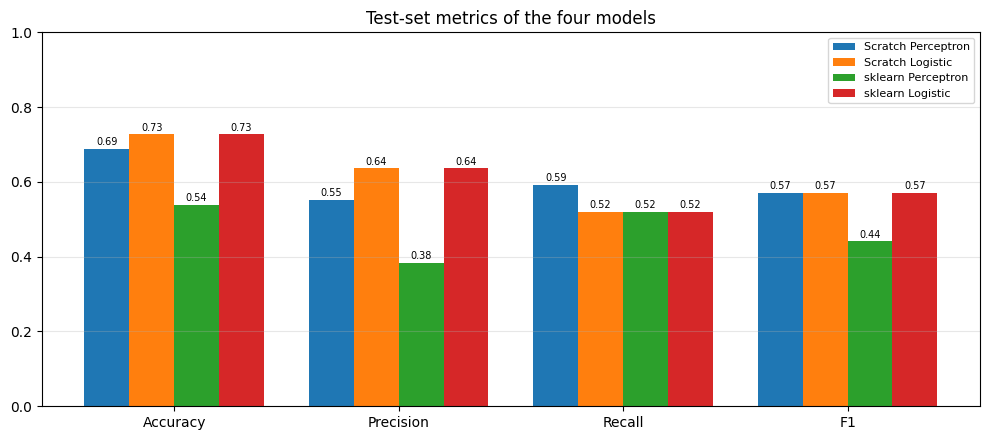

In [8]:
metric_names = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metric_names)); width = 0.2
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, (name, row) in enumerate(comparison.iterrows()):
    vals = [row[m] for m in metric_names]
    bars = ax.bar(x + (k - 1.5) * width, vals, width, label=name)
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(metric_names); ax.set_ylim(0, 1)
ax.set_title("Test-set metrics of the four models"); ax.legend(fontsize=8, loc="upper right")
ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## 6. How Reliable Are the Differences? (Bootstrap)

The test set has only 154 patients and **54 positives**, so recall is estimated from very few cases (one extra caught case changes recall by about 1.9 points). We resample the test set with replacement (2000 times) to get a rough 95% interval for recall and accuracy.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
n = len(y_test)
B = 2000
idx = rng.integers(0, n, size=(B, n))

boot = {}
for name, p in test_pred.items():
    rec, acc = [], []
    for ix in idx:
        yt, yp = y_test[ix], p[ix]
        pos = yt == 1
        rec.append((yp[pos] == 1).mean() if pos.any() else np.nan)
        acc.append((yt == yp).mean())
    boot[name] = {"Recall 95% CI": f"[{np.nanpercentile(rec, 2.5):.2f}, {np.nanpercentile(rec, 97.5):.2f}]",
                  "Accuracy 95% CI": f"[{np.percentile(acc, 2.5):.2f}, {np.percentile(acc, 97.5):.2f}]"}
print(pd.DataFrame(boot).T.to_string())

                   Recall 95% CI Accuracy 95% CI
Scratch Perceptron  [0.46, 0.72]    [0.61, 0.76]
Scratch Logistic    [0.38, 0.65]    [0.66, 0.79]
sklearn Perceptron  [0.39, 0.65]    [0.46, 0.61]
sklearn Logistic    [0.38, 0.65]    [0.66, 0.79]


The intervals for the scratch Perceptron, scratch Logistic and sklearn Logistic overlap heavily on recall. So small gaps in recall between them (a few patients) are **within sampling noise** and should not be over-interpreted. A large gap, like the sklearn Perceptron's accuracy, is a different matter.

## 7. Cost-Sensitive Decision: Missing a Positive Case Costs More Than a False Alarm

For screening, a **false negative** (a diabetic patient told "no diabetes") delays diagnosis and treatment, whereas a **false positive** costs a follow-up test. So we care first about **recall** (and the FN count in the confusion matrix), and then about keeping precision and overall accuracy from collapsing.

In [10]:
cost_view = comparison[["FN", "FP", "Recall", "Precision", "Accuracy"]].copy()
cost_view["Missed positives (%)"] = (100 * cost_view["FN"] / y_test.sum()).round(1)
cost_view["False alarms (%)"]    = (100 * cost_view["FP"] / (1 - y_test).sum()).round(1)
print(cost_view.sort_values(["Recall", "Precision"], ascending=False).to_string())

                    FN  FP  Recall  Precision  Accuracy  Missed positives (%)  False alarms (%)
Scratch Perceptron  22  26   0.593      0.552     0.688                  40.7              26.0
Scratch Logistic    26  16   0.519      0.636     0.727                  48.1              16.0
sklearn Logistic    26  16   0.519      0.636     0.727                  48.1              16.0
sklearn Perceptron  26  45   0.519      0.384     0.539                  48.1              45.0


### 7.1 What can we choose among the four models as they are?

Look at the table and confusion matrices above, in this order:

1. **sklearn Perceptron** is the weakest model overall: accuracy is close to chance and it also produces by far the most false alarms, so it is not a candidate in spite of an average recall.
2. **Scratch Perceptron** has the highest recall of the four, i.e. the fewest missed cases, at the price of more false alarms and lower accuracy and precision than the logistic models.
3. **Logistic Regression** (scratch and sklearn give the same predictions) has the best accuracy and precision, but misses more positives than the scratch Perceptron at the default 0.5 threshold.

If we must choose strictly among the four fixed classifiers on **recall**, the scratch Perceptron is ahead. But the lead is a handful of patients (see the bootstrap), it comes from a single noisy final weight vector that is highly seed-dependent (Task 3, Section 8), and it offers no probability to tune. So it is a **fragile** choice.

### 7.2 A better option: Logistic Regression with a lower decision threshold

Logistic Regression outputs a probability, so we can trade precision for recall by moving the threshold below 0.5. A Perceptron cannot do this, because the step function has only a hard cut.

To avoid test-set leakage, the threshold is **chosen on the training set only**, and the test set is used once afterwards. The rule is simple and transparent: *pick the highest threshold whose training recall is at least 80 %* (a screening target stated before looking at any test result). Choosing the highest such threshold keeps false alarms as low as possible while meeting the recall target.

Threshold chosen on TRAINING data (highest t with training recall >= 80%): 0.26


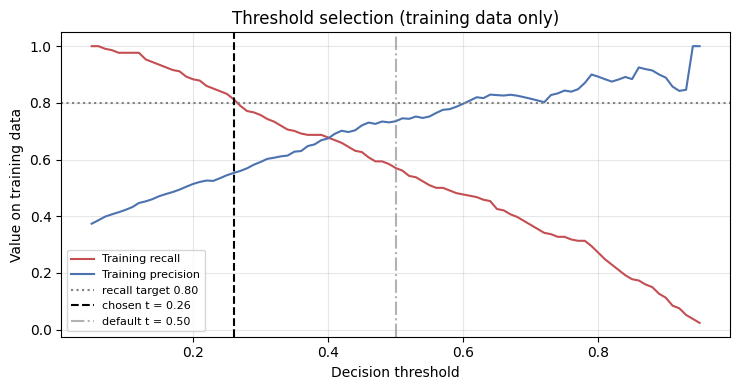

In [11]:
TARGET_RECALL = 0.80
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
train_proba = logit_scratch.predict_proba(X_train)
train_recall = np.array([metrics_manual(y_train, (train_proba >= t).astype(int))["Recall"] for t in thresholds])
train_prec   = np.array([metrics_manual(y_train, (train_proba >= t).astype(int))["Precision"] for t in thresholds])

ok = thresholds[train_recall >= TARGET_RECALL]
best_t = float(ok.max())
print("Threshold chosen on TRAINING data (highest t with training recall >= %.0f%%): %.2f" % (100 * TARGET_RECALL, best_t))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(thresholds, train_recall, label="Training recall", color="#C44E52")
ax.plot(thresholds, train_prec, label="Training precision", color="#4C72B0")
ax.axhline(TARGET_RECALL, color="gray", ls=":", label="recall target 0.80")
ax.axvline(best_t, color="k", ls="--", label=f"chosen t = {best_t:.2f}")
ax.axvline(0.5, color="gray", ls="-.", alpha=.6, label="default t = 0.50")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Value on training data")
ax.set_title("Threshold selection (training data only)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [12]:
test_proba = logit_scratch.predict_proba(X_test)
pred_tuned = (test_proba >= best_t).astype(int)
tuned_name = f"Scratch Logistic (t={best_t:.2f})"
test_pred_all = dict(test_pred)
test_pred_all[tuned_name] = pred_tuned

final = pd.DataFrame({n_: metrics_manual(y_test, p) for n_, p in test_pred_all.items()}).T
final[["TN", "FP", "FN", "TP"]] = final[["TN", "FP", "FN", "TP"]].astype(int)
final[["Accuracy", "Precision", "Recall", "F1"]] = final[["Accuracy", "Precision", "Recall", "F1"]].astype(float).round(3)
print(final.to_string())

cm_t = confusion_matrix_manual(y_test, pred_tuned)
cm_d = confusion_matrix_manual(y_test, test_pred["Scratch Logistic"])
print("\nTuned vs default logistic: missed positives %d -> %d, false alarms %d -> %d"
      % (cm_d[1, 0], cm_t[1, 0], cm_d[0, 1], cm_t[0, 1]))

                           TN  FP  FN  TP  Accuracy  Precision  Recall     F1
Scratch Perceptron         74  26  22  32     0.688      0.552   0.593  0.571
Scratch Logistic           84  16  26  28     0.727      0.636   0.519  0.571
sklearn Perceptron         55  45  26  28     0.539      0.384   0.519  0.441
sklearn Logistic           84  16  26  28     0.727      0.636   0.519  0.571
Scratch Logistic (t=0.26)  65  35  15  39     0.675      0.527   0.722  0.609

Tuned vs default logistic: missed positives 26 -> 15, false alarms 16 -> 35


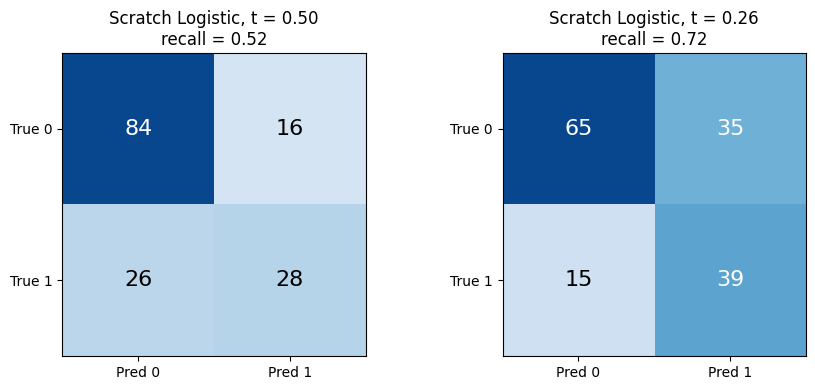

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, cm) in zip(axes, [("Scratch Logistic, t = 0.50", cm_d),
                                  (f"Scratch Logistic, t = {best_t:.2f}", cm_t)]):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True 0", "True 1"])
    ax.set_title(title + f"\nrecall = {cm[1,1]/(cm[1,0]+cm[1,1]):.2f}")
plt.tight_layout(); plt.show()

### 7.3 The recall / false-alarm trade-off (illustration only)

The table shows what different thresholds would do on the test set. It is **for understanding the trade-off, not for choosing the threshold**: picking a threshold by looking at test results would leak test information. The chosen threshold above was fixed using training data only.

In [14]:
rows = []
for t in [0.50, 0.40, best_t, 0.20, 0.12]:
    m = metrics_manual(y_test, (test_proba >= t).astype(int))
    rows.append({"threshold": t, "FN": m["FN"], "FP": m["FP"], "Recall": round(m["Recall"], 3),
                 "Precision": round(m["Precision"], 3), "Accuracy": round(m["Accuracy"], 3)})
print(pd.DataFrame(rows).drop_duplicates("threshold").set_index("threshold").to_string())
print("\nBaseline 'predict 0 for everyone': accuracy = %.3f. Very low thresholds flag almost everybody:"
      " recall rises, but false alarms explode and accuracy falls below this baseline." % base["Accuracy"])

           FN  FP  Recall  Precision  Accuracy
threshold                                     
0.50       26  16   0.519      0.636     0.727
0.40       23  26   0.574      0.544     0.682
0.26       15  35   0.722      0.527     0.675
0.20        8  42   0.852      0.523     0.675
0.12        2  60   0.963      0.464     0.597

Baseline 'predict 0 for everyone': accuracy = 0.649. Very low thresholds flag almost everybody: recall rises, but false alarms explode and accuracy falls below this baseline.


## 8. Conclusion

In [15]:
# programmatic summary so the printed numbers always match the tables above
four = comparison.copy()
best_four_recall = four["Recall"].astype(float).idxmax()
print("Highest recall among the four fixed models :", best_four_recall,
      "(recall = %.3f, FN = %d)" % (four.loc[best_four_recall, "Recall"], four.loc[best_four_recall, "FN"]))
print("Highest accuracy among the four fixed models:", four["Accuracy"].astype(float).idxmax(),
      "(accuracy = %.3f)" % four["Accuracy"].astype(float).max())
t_row = final.loc[f"Scratch Logistic (t={best_t:.2f})"]
print("Tuned logistic (t = %.2f): recall = %.3f, FN = %d, FP = %d, precision = %.3f, accuracy = %.3f"
      % (best_t, t_row["Recall"], t_row["FN"], t_row["FP"], t_row["Precision"], t_row["Accuracy"]))

Highest recall among the four fixed models : Scratch Perceptron (recall = 0.593, FN = 22)
Highest accuracy among the four fixed models: Scratch Logistic (accuracy = 0.727)
Tuned logistic (t = 0.26): recall = 0.722, FN = 15, FP = 35, precision = 0.527, accuracy = 0.675


## Conclusion

**Preferred model for screening (a missed case costs more than a false alarm): Logistic Regression, with the decision threshold lowered to the value chosen on the training data.**

Numbers on the held-out test set (54 positives, 100 negatives):

| Model | FN (missed) | FP (false alarms) | Recall | Precision | Accuracy |
|---|---|---|---|---|---|
| Scratch Perceptron | 22 | 26 | 0.593 | 0.552 | 0.688 |
| Scratch Logistic (t = 0.50) | 26 | 16 | 0.519 | 0.636 | 0.727 |
| sklearn Logistic (t = 0.50) | 26 | 16 | 0.519 | 0.636 | 0.727 |
| sklearn Perceptron | 26 | 45 | 0.519 | 0.384 | 0.539 |
| **Scratch Logistic (t = 0.26)** | **15** | 35 | **0.722** | 0.527 | 0.675 |

**Reasoning**

1. **Accuracy alone would pick the wrong model.** Logistic Regression at t = 0.50 has the best accuracy (0.727), but it misses 26 of 54 diabetic patients (48 %). The trivial rule "predict 0 for everyone" already scores 0.649 accuracy while catching nobody. So accuracy hides the failure we care about.
2. **Among the four fixed classifiers,** the scratch Perceptron has the highest recall (0.593, 22 missed), but its lead over logistic is only 4 patients, inside the bootstrap noise (Section 6), and it depends on one noisy final weight vector (very seed-dependent, Task 3). The sklearn Perceptron is clearly the worst: it has the most false alarms and near-chance accuracy.
3. **Logistic Regression with a lower threshold is the best way to reduce misses.** Because it outputs probabilities, the threshold can be moved to meet a recall target. Choosing t = 0.26 on training data only (highest threshold with at least 80 % training recall) cuts missed cases from 26 to 15 on the test set (recall 0.52 to 0.72), better than any of the four default models, at the price of more false alarms (16 to 35) and lower precision and accuracy.
4. **The trade-off is real and is a policy decision.** Test recall (0.72) came out below the 80 % training target, as expected with a small test set and a model that sees only two features. Lowering the threshold further would catch more positives but flag far more healthy patients (Section 7.3), so the final threshold should depend on how costly follow-up tests are.

**Limitations**

- Only two predictors (Glucose, BMI) are used, and the classes overlap heavily, so no linear model on these features can reach high recall without many false alarms.
- The test set is small (54 positives); one patient changes recall by about 1.9 points. A cross-validated comparison would be more reliable.
- This is an educational dataset, not a clinical decision tool.

## 9. Save Final Results

In [16]:
final.to_csv("task4_model_comparison.csv")
print("Saved task4_model_comparison.csv")

Saved task4_model_comparison.csv
